In [1]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
    --------------------------------------- 1.6/100.2 MB 8.4 MB/s eta 0:00:12
   - -------------------------------------- 3.4/100.2 MB 8.8 MB/s eta 0:00:12
   -- ------------------------------------- 5.8/100.2 MB 9.3 MB/s eta 0:00:11
   --- ------------------------------------ 7.9/100.2 MB 9.2 MB/s eta 0:00:11
   ---- ----------------------------------- 10.2/100.2 MB 9.8 MB/s eta 0:00:10
   ---- ----------------------------------- 11.5/100.2 MB 9.8 MB/s eta 0:00:10
   ----- ---------------------------------- 13.9/100.2 MB 9.2 MB/s eta 0:00:10
   ------ --------------------------------- 16.3/100.2 MB 9.4 MB/s eta 0:00:09
   ------- -------------------------------- 18.4/100.2 MB 9.6 MB/s eta 0:00:09
   -------- ------------------------------- 20.7/100.2 MB 9.6 MB/s eta 0:00:09
   --------- ------------------------------ 23.3/100.2 MB 9.8 MB/s eta 0:00:08
   --------- ------------------------------ 24.9/100.2 MB 9.6 MB

In [2]:
import json, csv, time, zipfile
import numpy as np
import matplotlib.pyplot as plt
import importlib, evalkit; importlib.reload(evalkit); from evalkit import *
from pathlib import Path

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent
EXTRACT_DIR = PROJECT_DIR / "data" / "sen2fire"
HIST_PATH = PROJECT_DIR / "data" / "baseline_hist.npz"
RF_PATH = PROJECT_DIR / "data" / "rf_samples.npz"

In [3]:
REF_ZIP = PROJECT_DIR / "data" / "reference" / "Baseline_code.zip"
REF_ZIP.parent.mkdir(parents=True, exist_ok=True)
print("Folder ready :", REF_ZIP.parent)
print("Zip present  :", REF_ZIP.exists())

if REF_ZIP.exists():
    with zipfile.ZipFile(REF_ZIP) as zf:
        for info in zf.infolist():
            print(f"{info.file_size:>10,d}  {info.filename}")
    with zipfile.ZipFile(REF_ZIP) as zf:
        text = zf.read("dataset/Sen2Fire_Dataset.py").decode("utf-8", errors="replace")

        for n, line in enumerate(text.splitlines(), start=1):
            print(f"{n:3d}  {line}")

Folder ready : g:\sen2fire-thesis\data\reference
Zip present  : True
         0  dataset/__init__.py
     7,083  dataset/Sen2Fire_Dataset.py
    15,721  dataset/test.txt
    45,682  dataset/train.txt
    15,676  dataset/val.txt
         0  model/__init__.py
     3,157  model/Networks.py
     8,301  Test.py
    13,787  Train.py
         0  utils/__init__.py
     2,769  utils/tools.py
  1  import os.path as osp
  2  import numpy as np
  3  from torch.utils import data
  4  from tqdm import tqdm
  5  
  6  modename = ['all_bands',                        #0
  7              'all_bands_aerosol',                #1
  8              'rgb',                              #2
  9              'rgb_aerosol',                      #3
 10              'swir',                             #4
 11              'swir_aerosol',                     #5
 12              'nbr',                              #6
 13              'nbr_aerosol',                      #7   
 14              'ndvi',                     

In [4]:
splits = {}
with zipfile.ZipFile(REF_ZIP) as zf:
    for name in ["train", "val", "test"]:
        raw = zf.read(f"dataset/{name}.txt").decode("utf-8")
        splits[name] = [line.strip() for line in raw.splitlines() if line.strip()]

for name, items in splits.items():
    scenes = sorted({Path(i).parts[0] if len(Path(i).parts) > 1 else "(no folder)" for i in items})
    print(f"{name:5s}: {len(items):5d} entries | first: {items[0]} | folders: {scenes}")

all_on_disk = {f"{s}/{p.name}" for s in ["scene1", "scene2", "scene3", "scene4"]
               for p in (EXTRACT_DIR / s).glob("*.npz")}

for name, items in splits.items():
    norm = [i.replace("\\", "/") for i in items]
    missing = [i for i in norm if i not in all_on_disk]
    print(f"{name:5s}: missing on disk = {len(missing)}", missing[:3])

sets = {k: {i.replace("\\", "/") for i in v} for k, v in splits.items()}
print("train & val overlap :", len(sets["train"] & sets["val"]))
print("train & test overlap:", len(sets["train"] & sets["test"]))
print("val & test overlap  :", len(sets["val"] & sets["test"]))
print("on disk but in no split:", len(all_on_disk - sets["train"] - sets["val"] - sets["test"]))

train:  1458 entries | first: scene1/scene_1_patch_1_1.npz | folders: ['scene1', 'scene2']
val  :   504 entries | first: scene3/scene_3_patch_1_1.npz | folders: ['scene3']
test :   504 entries | first: scene4/scene_4_patch_1_1.npz | folders: ['scene4']
train: missing on disk = 0 []
val  : missing on disk = 0 []
test : missing on disk = 0 []
train & val overlap : 0
train & test overlap: 0
val & test overlap  : 0
on disk but in no split: 0


In [5]:
d = np.load(HIST_PATH)
Hva, pva = d["Hva"], d["pva"]
pos_h = Hva[:, 1].sum(axis=0).reshape(50, 60).astype(np.float64)
neg_h = Hva[:, 0].sum(axis=0).reshape(50, 60).astype(np.float64)
TP = pos_h[5:, 23:].sum(); FP = neg_h[5:, 23:].sum(); FN = float(pva.sum()) - TP
TN = Hva.shape[0] * PATCH_PX - TP - FP - FN
cm_thr_px = {"TP": TP, "FP": FP, "FN": FN, "TN": TN}
cm_thr_patch = {"TP": 56, "FP": 18, "FN": 38, "TN": 392}
print("threshold pixel :", {k: round(v, 3) for k, v in scores(cm_thr_px).items()})
print("threshold patch :", {k: round(v, 3) for k, v in scores(cm_thr_patch).items()})

threshold pixel : {'precision': np.float64(0.508), 'recall': np.float64(0.035), 'f1': np.float64(0.066), 'iou': np.float64(0.034), 'fpr': np.float64(0.001), 'prevalence': np.float64(0.036), 'flag_all_f1': np.float64(0.069)}
threshold patch : {'precision': 0.757, 'recall': 0.596, 'f1': 0.667, 'iou': 0.5, 'fpr': 0.044, 'prevalence': 0.187, 'flag_all_f1': 0.314}


In [6]:
from sklearn.ensemble import RandomForestClassifier

s = np.load(RF_PATH)
Xtr, ytr, gtr, Xva, yva = s["Xtr"], s["ytr"], s["ptr_id"], s["Xva"], s["yva"]
cols = list(range(13))

P = np.load(HIST_PATH)["ptr"].astype(np.float64)
n_pos_s = np.bincount(gtr[ytr == 1], minlength=len(P))
n_neg_s = np.bincount(gtr[ytr == 0], minlength=len(P))
w = np.where(ytr == 1, P[gtr] / np.maximum(n_pos_s[gtr], 1),
             (PATCH_PX - P[gtr]) / np.maximum(n_neg_s[gtr], 1))
mh = (np.random.default_rng(42).random(len(P)) < 0.2)[gtr]

rf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=10,
                            max_samples=0.3, n_jobs=-1, random_state=0)
rf.fit(Xtr[~mh][:, cols], ytr[~mh])
thr = best_f1_threshold(ytr[mh], rf.predict_proba(Xtr[mh][:, cols])[:, 1], w[mh])
pv = rf.predict_proba(Xva[:, cols])[:, 1]
w_val = np.full(len(yva), PATCH_PX / 2000)
cm_rf = confusion(yva, pv >= thr, w_val)
print("RF pixel        :", {k: round(v, 3) for k, v in scores(cm_rf).items()}, "AP", round(average_precision(yva, pv), 3))

RF pixel        : {'precision': 0.085, 'recall': 0.427, 'f1': 0.142, 'iou': 0.076, 'fpr': 0.17, 'prevalence': 0.036, 'flag_all_f1': 0.069} AP 0.092


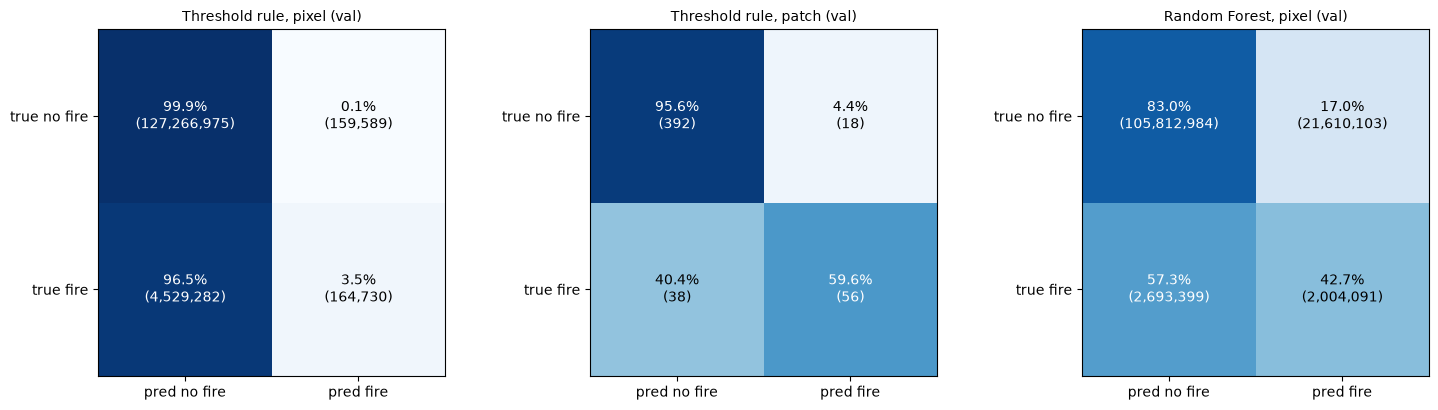

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
plot_confusion(cm_thr_px, "Threshold rule, pixel (val)", axes[0])
plot_confusion(cm_thr_patch, "Threshold rule, patch (val)", axes[1])
plot_confusion(cm_rf, "Random Forest, pixel (val)", axes[2])
plt.tight_layout()
plt.savefig(PROJECT_DIR / "results" / "confusion_matrices_val.png", dpi=130)
plt.show()

{'model': 'Random Forest', 'thr': 0.366, 'ap': 0.092, 'recall@fpr0.125%': 0.018, 'recall@fpr1%': 0.053, 'precision': 0.085, 'recall': 0.427, 'f1': 0.142, 'iou': 0.076, 'fpr': 0.17}
{'model': 'Logistic regression', 'thr': 0.292, 'ap': 0.125, 'recall@fpr0.125%': 0.04, 'recall@fpr1%': 0.093, 'precision': 0.096, 'recall': 0.374, 'f1': 0.153, 'iou': 0.083, 'fpr': 0.129}
{'model': 'CatBoost', 'thr': 0.36, 'ap': 0.103, 'recall@fpr0.125%': 0.018, 'recall@fpr1%': 0.072, 'precision': 0.092, 'recall': 0.439, 'f1': 0.151, 'iou': 0.082, 'fpr': 0.16}


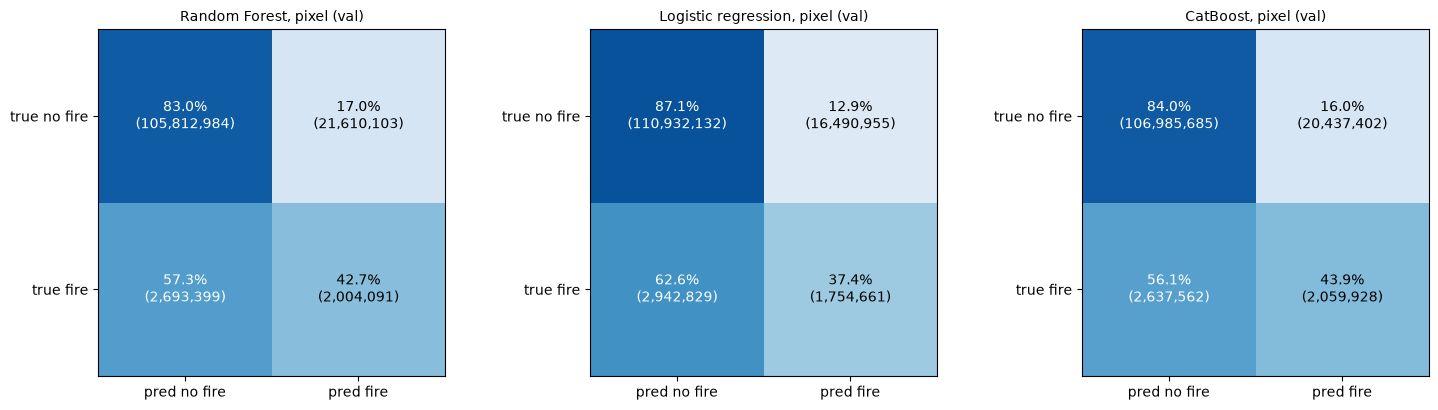

In [ ]:
import importlib, evalkit; importlib.reload(evalkit); from evalkit import *
import csv
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier

fpr_rule = 0.00125
Xfit, yfit = Xtr[~mh][:, cols], ytr[~mh]

def run_model(name, model, fit=True):
    if fit:
        model.fit(Xfit, yfit)
    thr = best_f1_threshold(ytr[mh], model.predict_proba(Xtr[mh][:, cols])[:, 1], w[mh])
    pv = model.predict_proba(Xva[:, cols])[:, 1]
    cm = confusion(yva, pv >= thr, w_val)
    row = {"model": name, "thr": round(thr, 3), "ap": round(average_precision(yva, pv), 3),
           "recall@fpr0.125%": round(recall_at_fpr(yva, pv, fpr_rule), 3),
           "recall@fpr1%": round(recall_at_fpr(yva, pv, 0.01), 3)}
    row.update({k: round(v, 3) for k, v in scores(cm).items() if k in ("precision", "recall", "f1", "iou", "fpr")})
    return row, cm

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
cb = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1, random_seed=0, verbose=0, thread_count=-1)

results, cms = [], {}
for name, model, fit in [("Random Forest", rf, False), ("Logistic regression", lr, True), ("CatBoost", cb, True)]:
    row, cm = run_model(name, model, fit)
    results.append(row); cms[name] = cm
    print(row)

with open(PROJECT_DIR / "results" / "tabular_models_val.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=list(results[0].keys()))
    wr.writeheader(); wr.writerows(results)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, cm) in zip(axes, cms.items()):
    plot_confusion(cm, f"{name}, pixel (val)", ax)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "results" / "confusion_matrices_tabular_val.png", dpi=130)
plt.show()

In [9]:
rng = np.random.default_rng(0)

def sample_split(items, n_pos, n_neg, n_uniform):
    Xs, ys, ps = [], [], []
    t0 = time.perf_counter()
    for i, rel in enumerate(items):
        with np.load(EXTRACT_DIR / rel) as d_:
            img = d_["image"]
            aer = d_["aerosol"].ravel().astype(np.float32)
            lb = (d_["label"] > 0).ravel()
        X = img.reshape(img.shape[0], -1).astype(np.float32)
        N = X.shape[1]
        if n_uniform:
            idx = rng.integers(0, N, size=n_uniform)
        else:
            pos_all = np.flatnonzero(lb)
            pos = rng.choice(pos_all, size=min(n_pos, len(pos_all)), replace=False) if len(pos_all) else pos_all
            cand = rng.integers(0, N, size=n_neg * 2)
            neg = cand[~lb[cand]][:n_neg]
            idx = np.concatenate([pos, neg])
        ratio = (X[11, idx] / np.maximum(X[10, idx], 1.0))[:, None]
        feats = np.hstack([X[:, idx].T, ratio, aer[idx][:, None]]).astype(np.float32)
        Xs.append(feats)
        ys.append(lb[idx].astype(np.uint8))
        ps.append(np.full(len(idx), i, dtype=np.int32))
        if (i + 1) % 300 == 0:
            print(f"{len(items)} patches, {i + 1} done ({time.perf_counter() - t0:.0f} s)")
    return np.vstack(Xs), np.concatenate(ys), np.concatenate(ps)

if RF_PATH.exists():
    print("Cache already exists, skipping.")
else:
    Xtr, ytr, ptr_id = sample_split(splits["train"], 1000, 1000, 0)
    Xva, yva, pva_id = sample_split(splits["val"], 0, 0, 2000)
    np.savez_compressed(RF_PATH, Xtr=Xtr, ytr=ytr, ptr_id=ptr_id, Xva=Xva, yva=yva, pva_id=pva_id)
    print("train sample:", Xtr.shape, "fire share:", round(float(ytr.mean()), 3))
    print("val sample:  ", Xva.shape, "fire share:", round(float(yva.mean()), 4), "(expect ~0.0355)")

Cache already exists, skipping.


In [10]:
RF3_PATH = PROJECT_DIR / "data" / "rf_samples_scene3_balanced.npz"
if RF3_PATH.exists():
    print("Cache already exists, skipping.")
else:
    X3, y3, g3 = sample_split(splits["val"], 1000, 1000, 0)
    np.savez_compressed(RF3_PATH, X3=X3, y3=y3, g3=g3)
    print("scene 3 balanced sample:", X3.shape, "fire share:", round(float(y3.mean()), 3))

504 patches, 300 done (74 s)
scene 3 balanced sample: (593019, 14) fire share: 0.154


In [11]:
import pandas as pd
z = np.load(RF3_PATH); X3, y3, g3 = z["X3"], z["y3"], z["g3"]
Pt = np.load(HIST_PATH)["ptr"].astype(float); Pv = np.load(HIST_PATH)["pva"].astype(float)

def nat_weights(y, g, P):
    n_pos = np.bincount(g[y == 1], minlength=len(P)); n_neg = np.bincount(g[y == 0], minlength=len(P))
    return np.where(y == 1, P[g] / np.maximum(n_pos[g], 1), (PATCH_PX - P[g]) / np.maximum(n_neg[g], 1))

sc_tr = np.array([1 if r.startswith("scene1") else 2 for r in splits["train"]])
X_all = np.vstack([Xtr, X3]); y_all = np.concatenate([ytr, y3])
w_all = np.concatenate([nat_weights(ytr, gtr, Pt), nat_weights(y3, g3, Pv)])
scene_all = np.concatenate([sc_tr[gtr], np.full(len(y3), 3)])
patch_all = np.concatenate([gtr, g3 + len(Pt)]).astype(int)

def make_models():
    return {"Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
            "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=10,
                                                    max_samples=0.3, n_jobs=-1, random_state=0),
            "CatBoost": CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1,
                                           random_seed=0, verbose=0, thread_count=-1)}

rows, rng_cv = [], np.random.default_rng(42)
for held in [1, 2, 3]:
    tr = scene_all != held; te = ~tr
    pids = np.unique(patch_all[tr])
    hold_ids = rng_cv.choice(pids, size=int(0.2 * len(pids)), replace=False)
    hmask = tr & np.isin(patch_all, hold_ids); fmask = tr & ~hmask
    for name, model in make_models().items():
        model.fit(X_all[fmask][:, cols], y_all[fmask])
        thr = best_f1_threshold(y_all[hmask], model.predict_proba(X_all[hmask][:, cols])[:, 1], w_all[hmask])
        s_te = model.predict_proba(X_all[te][:, cols])[:, 1]
        yt, wt = y_all[te], w_all[te]
        sc = scores(confusion(yt, s_te >= thr, wt)); ap = average_precision(yt, s_te, wt)
        rows.append(dict(held_out=held, model=name, ap=ap, lift=ap / sc["prevalence"],
                         r_fpr_0125=recall_at_fpr(yt, s_te, 0.00125, wt), r_fpr_1=recall_at_fpr(yt, s_te, 0.01, wt),
                         precision=sc["precision"], recall=sc["recall"], f1=sc["f1"]))
        print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rows[-1].items()})

df = pd.DataFrame(rows)
df.to_csv(PROJECT_DIR / "results" / "loso_scenes123_tabular.csv", index=False)
print(df.groupby("model")[["ap", "lift", "r_fpr_0125", "r_fpr_1", "f1"]].agg(["mean", "std"]).round(3))

{'held_out': 1, 'model': 'Logistic regression', 'ap': 0.179, 'lift': 5.223, 'r_fpr_0125': 0.027, 'r_fpr_1': 0.149, 'precision': 0.202, 'recall': 0.35, 'f1': 0.256}
{'held_out': 1, 'model': 'Random Forest', 'ap': 0.132, 'lift': 3.853, 'r_fpr_0125': 0.026, 'r_fpr_1': 0.109, 'precision': 0.268, 'recall': 0.12, 'f1': 0.166}
{'held_out': 1, 'model': 'CatBoost', 'ap': 0.119, 'lift': 3.458, 'r_fpr_0125': 0.03, 'r_fpr_1': 0.102, 'precision': 0.308, 'recall': 0.077, 'f1': 0.123}
{'held_out': 2, 'model': 'Logistic regression', 'ap': 0.043, 'lift': 3.78, 'r_fpr_0125': 0.032, 'r_fpr_1': 0.064, 'precision': 0.345, 'recall': 0.026, 'f1': 0.049}
{'held_out': 2, 'model': 'Random Forest', 'ap': 0.023, 'lift': 1.974, 'r_fpr_0125': 0.008, 'r_fpr_1': 0.054, 'precision': 0.036, 'recall': 0.111, 'f1': 0.054}
{'held_out': 2, 'model': 'CatBoost', 'ap': 0.019, 'lift': 1.62, 'r_fpr_0125': 0.001, 'r_fpr_1': 0.017, 'precision': 0.028, 'recall': 0.134, 'f1': 0.046}
{'held_out': 3, 'model': 'Logistic regression', '

In [12]:
meds = {1: [], 2: [], 3: []}
for split in ["train", "val"]:
    for rel in splits[split]:
        with np.load(EXTRACT_DIR / rel) as d_:
            meds[int(rel.split("/")[0][-1])].append(float(np.median(d_["aerosol"])))
scene_med = {k: float(np.median(v)) for k, v in meds.items()}
print(scene_med)

X_norm = X_all.copy()
X_norm[:, 13] = X_all[:, 13] - np.array([scene_med[s] for s in scene_all])
cols14 = list(range(14))

specs = [
    ("LR + aerosol (scene-norm)", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)), X_norm, cols14),
    ("RF shallow", lambda: RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=200,
                                                  max_samples=0.3, n_jobs=-1, random_state=0), X_all, cols),
    ("CatBoost shallow", lambda: CatBoostClassifier(iterations=200, depth=3, learning_rate=0.1, l2_leaf_reg=10,
                                                    random_seed=0, verbose=0, thread_count=-1), X_all, cols),
]

rows2, rng_cv = [], np.random.default_rng(42)
for held in [1, 2, 3]:
    tr = scene_all != held; te = ~tr
    pids = np.unique(patch_all[tr])
    hold_ids = rng_cv.choice(pids, size=int(0.2 * len(pids)), replace=False)
    hmask = tr & np.isin(patch_all, hold_ids); fmask = tr & ~hmask
    for name, factory, XM, cc in specs:
        model = factory()
        model.fit(XM[fmask][:, cc], y_all[fmask])
        thr = best_f1_threshold(y_all[hmask], model.predict_proba(XM[hmask][:, cc])[:, 1], w_all[hmask])
        s_te = model.predict_proba(XM[te][:, cc])[:, 1]
        yt, wt = y_all[te], w_all[te]
        sc = scores(confusion(yt, s_te >= thr, wt)); ap = average_precision(yt, s_te, wt)
        rows2.append(dict(held_out=held, model=name, ap=ap, lift=ap / sc["prevalence"],
                          r_fpr_0125=recall_at_fpr(yt, s_te, 0.00125, wt), r_fpr_1=recall_at_fpr(yt, s_te, 0.01, wt),
                          precision=sc["precision"], recall=sc["recall"], f1=sc["f1"]))
        print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rows2[-1].items()})

df2 = pd.concat([df, pd.DataFrame(rows2)], ignore_index=True)
df2.to_csv(PROJECT_DIR / "results" / "loso_scenes123_tabular_v2.csv", index=False)
print(df2.groupby("model")[["ap", "lift", "r_fpr_0125", "r_fpr_1"]].agg(["mean", "std"]).round(3))

{1: -0.6774045526981354, 2: -0.3159261792898178, 3: 0.917140930891037}
{'held_out': 1, 'model': 'LR + aerosol (scene-norm)', 'ap': 0.233, 'lift': 6.774, 'r_fpr_0125': 0.066, 'r_fpr_1': 0.22, 'precision': 0.119, 'recall': 0.5, 'f1': 0.192}
{'held_out': 1, 'model': 'RF shallow', 'ap': 0.158, 'lift': 4.602, 'r_fpr_0125': 0.019, 'r_fpr_1': 0.123, 'precision': 0.324, 'recall': 0.094, 'f1': 0.146}
{'held_out': 1, 'model': 'CatBoost shallow', 'ap': 0.15, 'lift': 4.354, 'r_fpr_0125': 0.027, 'r_fpr_1': 0.113, 'precision': 0.319, 'recall': 0.083, 'f1': 0.132}
{'held_out': 2, 'model': 'LR + aerosol (scene-norm)', 'ap': 0.051, 'lift': 4.447, 'r_fpr_0125': 0.03, 'r_fpr_1': 0.083, 'precision': 0.51, 'recall': 0.017, 'f1': 0.033}
{'held_out': 2, 'model': 'RF shallow', 'ap': 0.046, 'lift': 4.051, 'r_fpr_0125': 0.034, 'r_fpr_1': 0.066, 'precision': 0.067, 'recall': 0.071, 'f1': 0.069}
{'held_out': 2, 'model': 'CatBoost shallow', 'ap': 0.021, 'lift': 1.859, 'r_fpr_0125': 0.0, 'r_fpr_1': 0.029, 'precisio

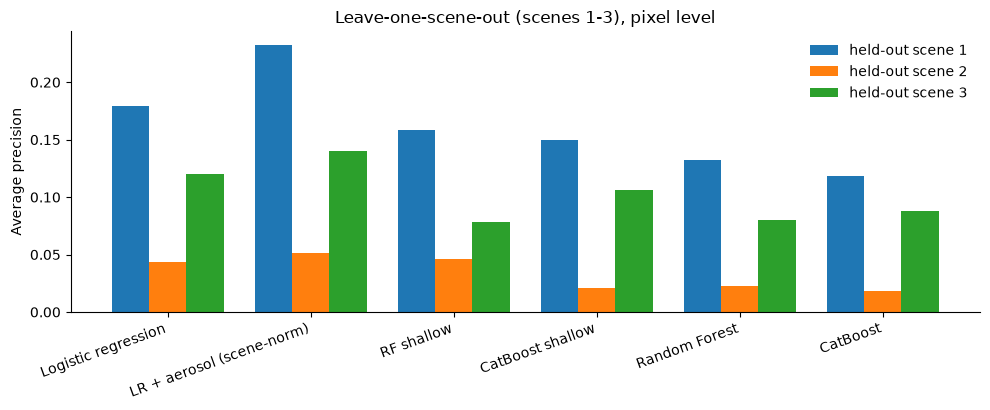

In [13]:
order = ["Logistic regression", "LR + aerosol (scene-norm)", "RF shallow", "CatBoost shallow", "Random Forest", "CatBoost"]
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(order)); wd = 0.26
for k, sc_ in enumerate([1, 2, 3]):
    vals = [df2[(df2.model == m) & (df2.held_out == sc_)]["ap"].iloc[0] for m in order]
    ax.bar(x + (k - 1) * wd, vals, wd, label=f"held-out scene {sc_}")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_ylabel("Average precision"); ax.legend(frameon=False)
ax.set_title("Leave-one-scene-out (scenes 1-3), pixel level")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(PROJECT_DIR / "results" / "loso_ap_by_fold.png", dpi=130); plt.show()